In [18]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import t as t_dist
from scipy.linalg import block_diag
from matplotlib.colors import TwoSlopeNorm, to_rgb

In [19]:
# ---- core model (Table 1) ----
S = 0.0005          # s: semantic feature -> lexical item weight
D = 0.05            # d: decay (retention = 1 - d)
SIGMA_A = 0.2       # a: SD of the activation-based noise
SIGMA_I = 0.0009    # i: SD of the intrinsic noise
ETA = 0.01          # eta: Hebbian learning rate
R = 150             # r: ms per time step (both tasks)
MAX_STEPS = 10000   # step limit per trial

# ---- PWI (Table 2) ----
F_PWI = 0.1         # f: input strength
K_PWI = 5.0         # k: selection threshold on conflict
L = 0.002           # l: letter <-> lexical item weight

# ---- PP (Table 2) ----
F_PP = 0.15         # f: input strength
K_PP = 5.5          # k: selection threshold on conflict
P_B = 0.005         # p_b: probe (small arrow, relevant) -> response weight
P_M = 0.006         # p_m: prime (big arrow, irrelevant) -> response weight (prepotent)

# ---- monitoring-control loop (Table 2) ----
W0 = 0.5                     # w_0: initial task -> dimension weight (and the value it is pulled back to)
A_T = np.array([1.45, 0.4])  # A_t of the task nodes: [relevant, irrelevant]
B = 1.4                      # B in [A_t - B]
LAM = 0.4                    # lambda in Eq. 9 (`lambda` is a reserved keyword in Python)
W_DI = 1.0                   # dimension -> stimulus weight (fixed)

In [ ]:
N_PARTICIPANTS = 5000
N_TRIAL = 128
N_JOBS = -1

FEAT = slice(0, 190)
WORD = slice(190, 215)
LETTER = slice(215, 290)
PWI = slice(0, 290)
PP_IN = slice(290, 298)
PP_RESP = slice(298, 302)
N_NODES = 302

DIM_TASK = np.array([0, 1, 1, 0])
PWI_DIMS = np.array([0, 1])
PP_DIMS = np.array([3, 2])
UNIT_DIM = -np.ones(N_NODES, dtype=int)
UNIT_DIM[FEAT] = 0
UNIT_DIM[LETTER] = 1
UNIT_DIM[294:298] = 2
UNIT_DIM[290:294] = 3


def init_weights(s=S, l=L, d=D, p_b=P_B, p_m=P_M):
    """302 x 302 weight matrix (row = sender, column = receiver); decay on the diagonal."""
    w_cat = np.zeros((38, 5))
    w_cat[:3, :] = s                                   # shared features -> every item of the category
    for i in range(5):
        w_cat[3 + 7 * i: 10 + 7 * i, i] = s            # unique features -> their own item
    w_fl = np.kron(np.eye(5), w_cat)                   # 190 x 25
    w_lp = np.kron(np.eye(25), l * np.ones(3))         # 25 x 75
    pwi = np.block([[(1 - d) * np.eye(190), w_fl, np.zeros((190, 75))],
                    [w_fl.T, (1 - d) * np.eye(25), w_lp],
                    [np.zeros((75, 190)), w_lp.T, (1 - d) * np.eye(75)]])
    pp = (1 - d) * np.eye(12)
    pp[0:4, 8:12] = p_b * np.eye(4)
    pp[4:8, 8:12] = p_m * np.eye(4)
    return block_diag(pwi, pp)


W_INIT = init_weights()


def dim_activation(w_td, present):
    """A_d = w_td * A_t for the dimensions present on this trial (0 otherwise); fixed within a trial."""
    a = np.zeros(4)
    a[present] = w_td[present] * A_T[DIM_TASK[present]]
    return a


def gain_from_dims(a_dim):
    """g_i = w_di * A_d of the dimension feeding node i (0 for nodes without a dimension)."""
    g = np.zeros(N_NODES)
    has = UNIT_DIM >= 0
    g[has] = W_DI * a_dim[UNIT_DIM[has]]
    return g

In [21]:
def pwi_sequence(n):
    cond = np.random.permutation(np.r_[np.zeros((n + 1) // 2, int), np.ones(n // 2, int)])
    cat = np.r_[np.repeat(np.arange(5), n // 5), np.random.choice(5, n % 5, replace=False)]
    return cond, np.random.permutation(cat)


def pp_sequence(n):
    cond = np.random.permutation(np.r_[np.zeros(n // 2, int), np.ones(n // 2, int)])
    rel = np.random.permutation(np.repeat(np.arange(4), n // 4))
    irr = np.where(cond == 0, rel, (rel + np.random.randint(1, 4, n)) % 4)   # incongruent: another arrow
    return cond, rel, irr


def pwi_input(cat, cond, f=F_PWI):
    x = np.zeros(N_NODES)
    x[38 * cat: 38 * cat + 10] = f                     
    first = 215 + 15 * cat + 3 * cond
    x[first: first + 3] = f
    return x


def pp_input(rel, irr, f=F_PP):
    x = np.zeros(N_NODES)
    x[290 + rel] = f
    x[294 + irr] = f
    return x

In [22]:
def add_noise(a):
    """A(t) * N(0, a) + N(0, i)"""
    return np.random.normal(0, SIGMA_A, a.size) * np.abs(a) + np.random.normal(0, SIGMA_I, a.size)


def conflict_of(a):
    top2 = np.partition(a, -2)[-2:]
    return np.log(1 / (top2[1] - top2[0] + 1e-10))


def pwi_trial(x, w, gain, k=K_PWI):
    """Returns max conflict, final activation (290 PWI nodes), response (0-24), steps, timeout."""
    W = w[PWI, PWI]; X = x[PWI]; g = gain[PWI].copy()
    g[WORD] = 1.0                                       
    a = X.copy(); t = 0; conflict = np.inf; max_conflict = 0.0
    while conflict > k and t < MAX_STEPS:
        s = a + X                                       
        new = s @ W                                     
        new[WORD] = (g * s) @ W[:, WORD]                
        new += add_noise(a)
        a = np.maximum(new, 0)
        conflict = conflict_of(a[WORD])
        max_conflict = max(max_conflict, conflict)
        t += 1
    return max_conflict, a, int(np.argmax(a[WORD])), t, conflict > k


def pp_trial(x, w, gain, k=K_PP):
    """Feedforward (no response -> input feedback). Returns max conflict, response (0-3), steps, timeout."""
    W_in = w[PP_IN, PP_RESP]; X = x[PP_IN]; g = gain[PP_IN]
    stim = X.copy(); resp = np.zeros(4); t = 0; conflict = np.inf; max_conflict = 0.0
    while conflict > k and t < MAX_STEPS:
        s = stim + X
        new_stim = (1 - D) * s + add_noise(stim)
        new_resp = (1 - D) * resp + (g * s) @ W_in + add_noise(resp)
        stim = np.maximum(new_stim, 0); resp = np.maximum(new_resp, 0)
        conflict = conflict_of(resp)
        max_conflict = max(max_conflict, conflict)
        t += 1
    return max_conflict, int(np.argmax(resp)), t, conflict > k


def hebbian(w, a, eta=ETA):
    """Δw = eta * A_feature * A_item (symmetric), using the activation at selection."""
    w[WORD, FEAT] += eta * np.outer(a[WORD], a[FEAT])
    w[FEAT, WORD] = w[WORD, FEAT].T

In [23]:
DEFAULT_LEARN = A_T[DIM_TASK] - B     # [A_t - B] for [picture, word, big arrow, small arrow]


def monitor_update(w_td, a_dim, conflict, history, present, learn):
    dC = conflict - np.mean(history) if history else 0.0
    dw = dC * a_dim * learn
    w_td[present] = LAM * w_td[present] + (1 - LAM) * (W0 + dw[present])
    np.maximum(w_td, 0, out=w_td)


def run_participant(seed, mode='single', n_trial=N_TRIAL, learn=DEFAULT_LEARN):
    """mode = 'single' (PWI only, n_trial trials) or 'dual' (PWI, PP, PWI, PP, ...; n_trial per task).
       Returns per-trial arrays: task (0 = PWI, 1 = PP), cond (0 = C, 1 = I), steps, correct, timeout;
       and the largest w_td reached."""
    np.random.seed(seed)
    learn = np.asarray(learn, float)
    pwi_cond, pwi_cat = pwi_sequence(n_trial)
    if mode == 'dual':
        pp_cond, pp_rel, pp_irr = pp_sequence(n_trial)
        task = np.tile([0, 1], n_trial)
    else:
        task = np.zeros(n_trial, int)
    w = W_INIT.copy(); w_td = np.full(4, W0); history = {0: [], 1: []}
    n = len(task); out = {k: np.zeros(n, int) for k in ('cond', 'steps', 'correct', 'timeout')}
    w_max = w_td.max(); i_task = [0, 0]
    for i, tk in enumerate(task):
        j = i_task[tk]; i_task[tk] += 1
        present = PWI_DIMS if tk == 0 else PP_DIMS
        a_dim = dim_activation(w_td, present)
        gain = gain_from_dims(a_dim)
        if tk == 0:
            cond = pwi_cond[j]
            conflict, a, resp, steps, timeout = pwi_trial(pwi_input(pwi_cat[j], cond), w, gain)
            hebbian(w, a)
            correct = resp == 5 * pwi_cat[j]
        else:
            cond = pp_cond[j]
            conflict, resp, steps, timeout = pp_trial(pp_input(pp_rel[j], pp_irr[j]), w, gain)
            correct = resp == pp_rel[j]
        monitor_update(w_td, a_dim, conflict, history[tk], present, learn)
        history[tk].append(conflict)
        w_max = max(w_max, w_td.max())
        for k, v in (('cond', cond), ('steps', steps), ('correct', correct), ('timeout', timeout)):
            out[k][i] = v
    out['task'] = task
    return out, w_max

In [32]:
CELLS = ['cC', 'cI', 'iC', 'iI']
TASK_NAMES = {0: 'PWI', 1: 'PP'}


def previous_conditions(task, cond):
    """For each trial: cond of the previous trial of the same task (within) and of the
       immediately preceding trial of the other task (cross); -1 if there is none."""
    within = np.full(len(task), -1); cross = np.full(len(task), -1); last = {}
    for i, tk in enumerate(task):
        within[i] = last.get(tk, -1); last[tk] = cond[i]
        if i > 0 and task[i - 1] != tk:
            cross[i] = cond[i - 1]
    return within, cross


def cell_means(prev, cur, rt, err):
    rts, errs = [], []
    for p, c in ((0, 0), (0, 1), (1, 0), (1, 1)):
        m = (prev == p) & (cur == c)
        rts.append(rt[m].mean() if m.any() else np.nan)
        errs.append(err[m].mean() if m.any() else np.nan)
    return np.array(rts), np.array(errs)


def summarize(tr):
    """{(task, analysis): (RT ms [cC, cI, iC, iI], error % [cC, cI, iC, iI])} for one participant."""
    within, cross = previous_conditions(tr['task'], tr['cond'])
    rt = tr['steps'] * R; err = (1 - tr['correct']) * 100.0
    out = {}
    for tk in np.unique(tr['task']):
        m = tr['task'] == tk
        analyses = [('within', within)] + ([('cross', cross)] if len(np.unique(tr['task'])) > 1 else [])
        for name, prev in analyses:
            out[(TASK_NAMES[tk], name)] = cell_means(prev[m], tr['cond'][m], rt[m], err[m])
    return out


def gratton(x):
    """Per-participant CSE: (cI - cC) - (iI - iC)."""
    return (x[:, 1] - x[:, 0]) - (x[:, 3] - x[:, 2])


def ci95(x, axis=0):
    """Half-width of the t-based 95% CI of the mean."""
    n = np.sum(np.isfinite(x), axis=axis)
    return t_dist.ppf(0.975, n - 1) * np.nanstd(x, axis=axis, ddof=1) / np.sqrt(n)


def cse_summary(rt, err, label):
    g = gratton(rt)
    n = len(g); m = g.mean(); se = g.std(ddof=1) / np.sqrt(n); t = m / se
    p = 2 * t_dist.sf(abs(t), n - 1); h = ci95(g)

In [25]:
def fpts_plot(rt, err, title=None, rt_ylim=None, err_ylim=None, save=None):
    """Mean RT and error rate in cC, cI, iC, iI (x = previous trial; silver = current C, red = current I),
       error bars = 95% CI."""
    fig, axes = plt.subplots(1, 2, figsize=(6, 4), constrained_layout=True)
    for ax, x, ylabel, ylim in zip(axes, (rt, err), ('RT (ms)', 'Error Rate (%)'), (rt_ylim, err_ylim)):
        m, h = x.mean(0), ci95(x)
        for cur, (marker, color) in enumerate((('o', 'silver'), ('^', 'red'))):
            idx = [cur, 2 + cur]                       # [c-, i-] for this current condition
            ax.plot([0, 1], m[idx], color=color, linewidth=2)
            ax.errorbar([0, 1], m[idx], yerr=h[idx], fmt=marker, color=color, markersize=8,
                        capsize=5, linestyle='none')
        ax.set_xticks([0, 1]); ax.set_xticklabels(['c', 'i'])
        ax.set_xlabel('Previous Trial Condition'); ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
        if ylim is not None:
            ax.set_ylim(ylim)
    if title:
        fig.suptitle(title, fontsize=12)
    if save:
        fig.savefig(save, dpi=300, bbox_inches='tight')
    plt.show()


def cse_plot(rt, err, title=None, rt_ylim=None, err_ylim=None, save=None):
    """Congruency effect (I - C) after congruent (c) and incongruent (i) trials; error bars = 95% CI."""
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.8), constrained_layout=True)
    if title:
        fig.suptitle(title, fontsize=13, fontweight='bold', family='serif')
    for ax, x, name, unit, ylim in zip(axes, (rt, err), ('RT (ms)', 'Error (%)'), ('ms', '%'),
                                       (rt_ylim, err_ylim)):
        eff = np.column_stack([x[:, 1] - x[:, 0], x[:, 3] - x[:, 2]])   # after c, after i
        m, h = eff.mean(0), ci95(eff)
        ax.bar([0, 1], m, yerr=h, color=['silver', 'red'], width=0.8, capsize=6,
               error_kw=dict(elinewidth=1.2, capthick=1.2))
        ax.set_xticks([0, 1]); ax.set_xticklabels(['c', 'i'])
        ax.set_xlabel('Previous Trial Condition'); ax.set_ylabel(f'Congruency Effect ({unit})')
        ax.set_title(name)
        ax.set_ylim(ylim if ylim is not None else (min(0, (m - h).min() * 1.15), (m + h).max() * 1.15))
        ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
    if save:
        fig.savefig(save, dpi=300, bbox_inches='tight')
    plt.show()

In [27]:
def run_simulation(mode, n=N_PARTICIPANTS, n_jobs=N_JOBS):
    """n participants; participant k uses seed k (k = 0, ..., n - 1)."""
    seeds = range(n)
    t0 = time.time()
    res = Parallel(n_jobs=n_jobs)(delayed(run_participant)(int(s), mode) for s in seeds)
    trials = [r[0] for r in res]; w_max = np.array([r[1] for r in res])
    summaries = [summarize(tr) for tr in trials]
    arrays = {key: (np.array([s[key][0] for s in summaries]), np.array([s[key][1] for s in summaries]))
              for key in summaries[0]}
    n_to = sum(tr['timeout'].sum() for tr in trials); n_tr = sum(len(tr['task']) for tr in trials)
    return trials, arrays


def complete(rt, err):
    """Drop participants with an empty cell (should not happen with 128 trials)."""
    keep = np.isfinite(rt).all(1) & np.isfinite(err).all(1)
    if (~keep).any():
        print(f'  dropped {(~keep).sum()} participants with an empty cell')
    return rt[keep], err[keep]

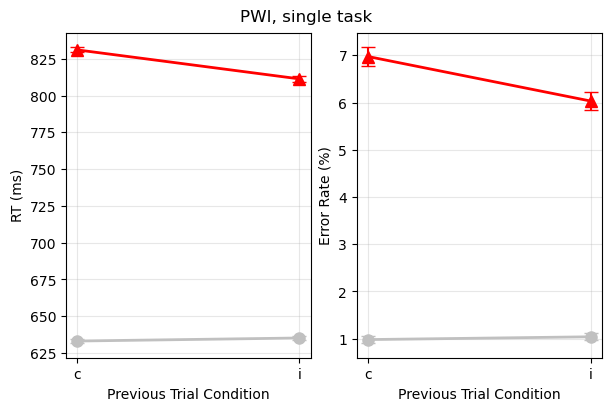

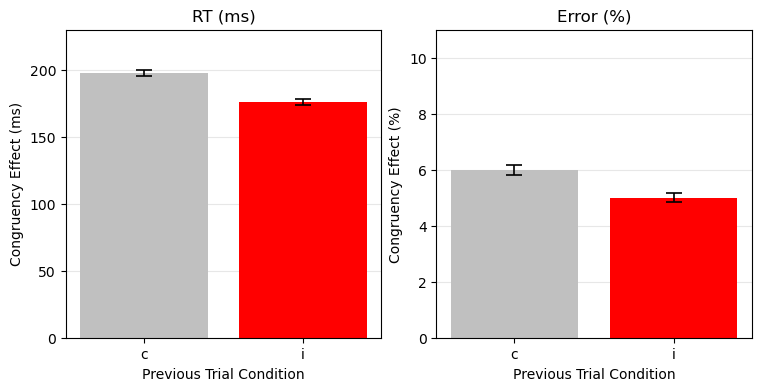

In [33]:
single_trials, single = run_simulation('single')
rt, err = complete(*single[('PWI', 'within')])
cse_summary(rt, err, 'PWI, single task')
fpts_plot(rt, err, 'PWI, single task', save='sim4_pwi_fpts.png')
cse_plot(rt, err, err_ylim = (0, 11), save='sim4_pwi_cse.png')

In [ ]:
dual_trials, dual = run_simulation('dual')
LABELS = {('PWI', 'within'): 'PWI, within-task', ('PP', 'within'): 'PP, within-task',
          ('PWI', 'cross'): 'PWI, cross-task', ('PP', 'cross'): 'PP, cross-task'}

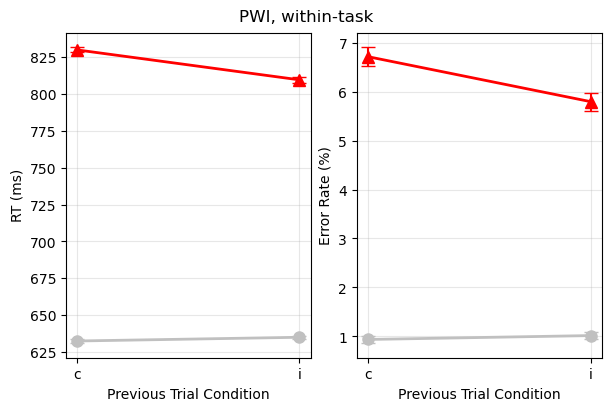

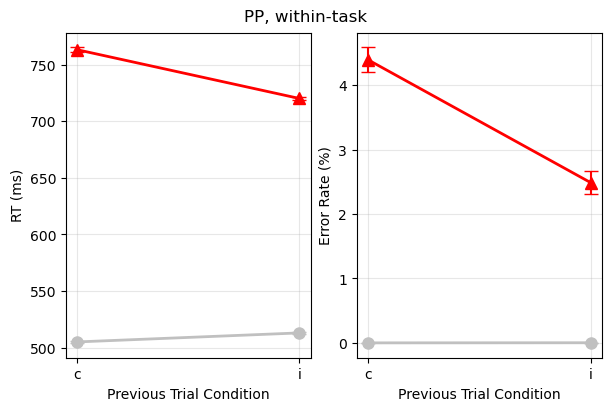

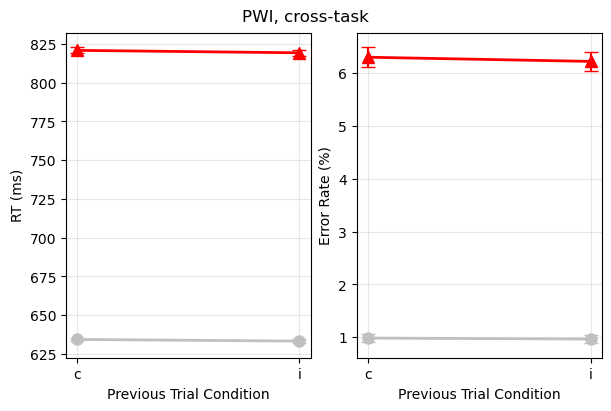

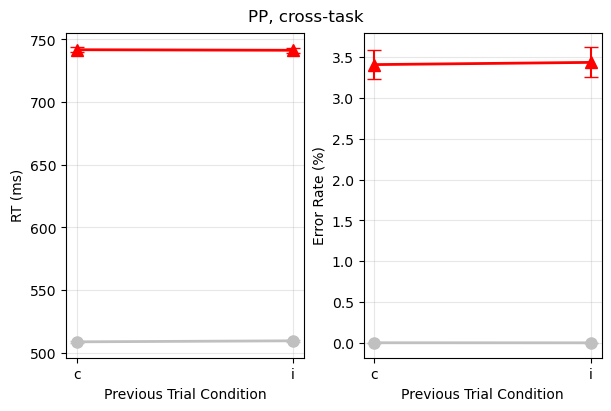

In [35]:
for key, label in LABELS.items():
    rt, err = complete(*dual[key])
    cse_summary(rt, err, label)
    fpts_plot(rt, err, label, save=f'sim5_{key[0].lower()}_{key[1]}_fpts.png')

In [36]:
COND_NAME = np.array(['congruent', 'incongruent'])

def means_to_df(arrays):
    rows = []
    for (task, analysis), (rt, err) in arrays.items():
        for p in range(len(rt)):
            for k, c in enumerate(CELLS):
                rows.append(dict(participant=p + 1, task=task, analysis=analysis, cell=c,
                                 prev=COND_NAME[int(c[0] == 'i')], curr=COND_NAME[int(c[1] == 'I')],
                                 RT_ms=rt[p, k], error_pct=err[p, k]))
    return pd.DataFrame(rows)

means_to_df(single).to_csv('sim4_pwi_means.csv', index=False)
means_to_df(dual).to_csv('sim5_dual_means.csv', index=False)

In [ ]:
FR_VALUES = [0, 0.02, 0.05, 0.08, 0.1, 0.2, 0.5, 1]
FI_VALUES = list(np.round(np.arange(-2.5, 2.51, 0.5), 2))
N_SEARCH = 1000


def search_participant(seed, fr, fi):
    tr, w_max = run_participant(seed, 'single', learn=[fr, fi, fi, fr])
    rt, err = summarize(tr)[('PWI', 'within')]
    return rt, err, w_max, tr['timeout'].sum()


def single_search(fr_values=FR_VALUES, fi_values=FI_VALUES, n=N_SEARCH,
                  n_jobs=N_JOBS, path='sim4_search.csv'):
    base = np.random.SeedSequence().entropy
    print(f'base seed = {base}')
    rows = []
    for cell, (fr, fi) in enumerate((a, b) for a in fr_values for b in fi_values):
        t0 = time.time()
        seeds = np.random.SeedSequence([base, cell]).generate_state(n)
        res = Parallel(n_jobs=n_jobs)(delayed(search_participant)(int(s), fr, fi) for s in seeds)
        rt, err, w_max, n_to = [np.array(x, dtype=float) for x in zip(*res)]
        keep = np.isfinite(rt).all(1) & np.isfinite(err).all(1)
        g = gratton(rt[keep]); se = g.std(ddof=1) / np.sqrt(len(g))
        e = err[keep].mean(0)
        rows.append(dict(fr=fr, fi=fi, base_seed=str(base), cell=cell, n=int(keep.sum()),
                         cse=g.mean(), se=se, t=g.mean() / se,
                         **{f'err_{c}': v for c, v in zip(CELLS, e)}))
        pd.DataFrame(rows).to_csv(path, index=False)
        r = rows[-1]
        print(f"fr={fr:g} fi={fi:g}  CSE {r['cse']:6.1f} ms  t={r['t']:6.2f}  err {np.round(e, 1)}  "
              f"runaway {r['runaway_pct']:.1f}%  ({time.time() - t0:.0f} s)", flush=True)
    return pd.DataFrame(rows)


search = single_search()

In [43]:
def plot_t_gray(df, x_col='fi', y_col='fr', t_col='t', n_col='n', extra_gray=None, gray_nonsig=True,
                x_label=r'$A_{t\text{-}IR}-B$', y_label=r'$A_{t\text{-}R}-B$', cbar_label='t', sig=0.05,
                vlim=5, mark=None, annot_size=9, gray='#d4d4d2', cmap='viridis', figsize=(7.5, 6.2),
                save_path=None):
    """Heatmap of per-cell t. Gray = two-sided p >= sig."""
    cmap = plt.get_cmap(cmap)
    ys = np.sort(df[y_col].unique()); xs = np.sort(df[x_col].unique())
    piv = lambda c: df.pivot(index=y_col, columns=x_col, values=c).loc[ys, xs].to_numpy()
    T = piv(t_col).astype(float)
    p = 2 * t_dist.sf(np.abs(T), int(df[n_col].min()) - 1)
    grey = ~(p < sig) if gray_nonsig else np.zeros(T.shape, dtype=bool)
    if extra_gray:
        grey |= piv(extra_gray).astype(bool)
    norm = TwoSlopeNorm(vcenter=0, vmin=-vlim, vmax=vlim)
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    im = ax.imshow(T, cmap=cmap, norm=norm, origin='lower', aspect='auto')
    ax.set_xticks(range(len(xs))); ax.set_xticklabels([f'{x:g}' for x in xs], rotation=45)
    ax.set_yticks(range(len(ys))); ax.set_yticklabels([f'{y:g}' for y in ys])
    ax.set_xlabel(x_label); ax.set_ylabel(y_label)
    for i in range(len(ys)):
        for j in range(len(xs)):
            if grey[i, j]:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color=gray, zorder=2))
                ink = '#1a1a19'
            else:
                r, g, b = to_rgb(cmap(norm(T[i, j])))
                ink = '#1a1a19' if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.55 else '#fcfcfb'
            ax.text(j, i, f'{T[i, j]:.1f}', ha='center', va='center', fontsize=annot_size, color=ink, zorder=3)
    if mark is not None:
        jx = np.where(np.isclose(xs, mark[0]))[0]; iy = np.where(np.isclose(ys, mark[1]))[0]
        if len(jx) and len(iy):
            ax.add_patch(plt.Rectangle((jx[0] - .5, iy[0] - .5), 1, 1, fill=False, edgecolor='black',
                                       linewidth=2.5, zorder=5))
    ax.set_xticks(np.arange(-.5, len(xs)), minor=True); ax.set_yticks(np.arange(-.5, len(ys)), minor=True)
    ax.set_axisbelow(False)
    ax.grid(which='minor', color='white', linewidth=1.5); ax.tick_params(which='minor', length=0)
    fig.colorbar(im, ax=ax, shrink=0.85, extend='both', label=cbar_label)
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

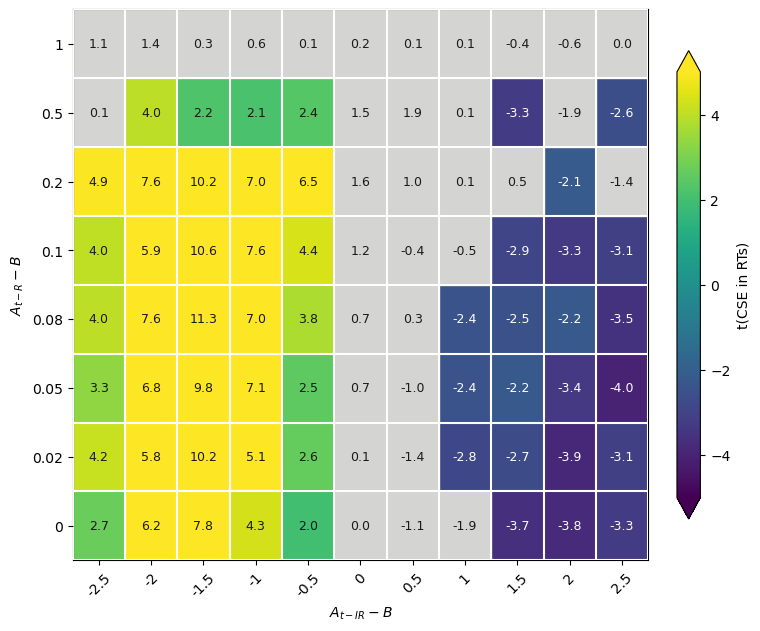

In [ ]:
plot_t_gray(search, 'fi', 'fr', t_col='t', n_col='n',
            x_label=r'$A_{t-IR}-B$', y_label=r'$A_{t-R}-B$',
            cbar_label='t(CSE in RTs)', save_path='pwi_single_t.png')